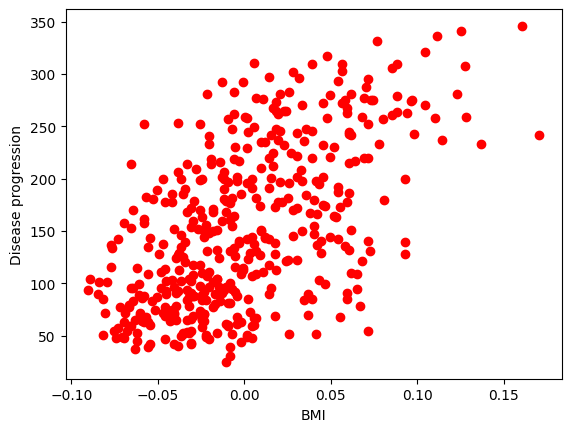

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_diabetes

# Load the dataset
data = load_diabetes()

# Select only the BMI feature
X = data.data[:, [2]]
Y = data.target

# Plot the data
plt.scatter(X, Y, color="red")
plt.xlabel("BMI")
plt.ylabel("Disease progression")
plt.show()

In [2]:
from sklearn.linear_model import LinearRegression

# Preprocessing: reshape into a matrix
reX = X.reshape(-1, 1)

# Create the model
model = LinearRegression()

# Train the model => find a 'w'
model.fit(reX, Y)

# Check the results
print("Weight:", model.coef_)
print("Constant:", model.intercept_)

Weight: [949.43526038]
Constant: 152.13348416289617


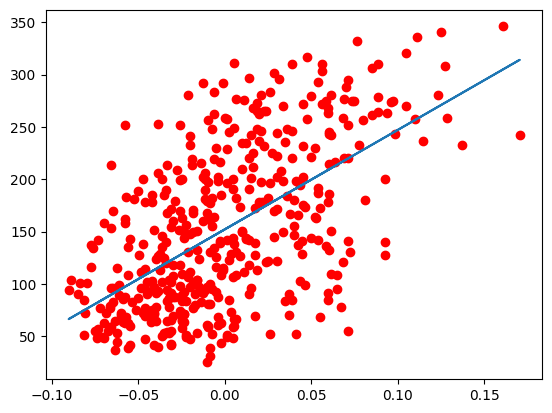

In [3]:
y_pred = model.predict(reX)  # Generate predictions

plt.scatter(X, Y, color="red")  # Original data (points)
plt.plot(X, y_pred)  # Predicted values for X (line)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,Y, test_size=0.33, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(296, 1)
(146, 1)
(296,)
(146,)


In [5]:
from sklearn.metrics import mean_squared_error

y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]

mean_squared_error(y_true, y_pred)

0.375

In [6]:
from sklearn.metrics import root_mean_squared_error

y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]

root_mean_squared_error(y_true, y_pred)
#np.sqrt(mean_squared_error(y_true, y_pred))

0.6123724356957945

In [7]:
from sklearn.metrics import mean_absolute_error

y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]

mean_absolute_error(y_true, y_pred)

0.5

In [8]:
from sklearn.metrics import r2_score

y_true = [3, -0.5, 2, 7]
y_pred = [2.5, 0.0, 2, 8]

r2_score(y_true, y_pred)

0.9486081370449679

In [9]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [10]:
#Removing Missing Values
df = df.dropna()
df.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,0
weight,0
acceleration,0
model_year,0
origin,0
name,0


In [11]:
# Select columns to use
col = ["weight", "horsepower", "displacement"]

X = df[col]
X.head()

,weight,horsepower,displacement
0,3504,130.0,307.0
1,3693,165.0,350.0
2,3436,150.0,318.0
3,3433,150.0,304.0
4,3449,140.0,302.0


In [12]:
# Extract the target values
y = df["mpg"]

# Check the final shapes of X and y
print(X.shape)
print(y.shape)

(392, 3)
(392,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((262, 3), (130, 3), (262,), (130,))

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)  # Calculate the mean and standard deviation from the training data

scaled_X_train = scaler.transform(X_train)  # Transform the training data
scaled_X_test = scaler.transform(X_test)  # Transform the test data

scaled_X_train[:5]  # NumPy array: use slicing instead of head()

array([[ 0.28638242,  1.01467949,  1.04310729],
       [-0.96190605, -0.89251284, -0.85460123],
       [-1.23996083, -0.61610816, -0.9220325 ],
       [-0.54778191, -0.39498441, -0.69083958],
       [ 0.00241158, -0.47790581,  0.06053739]])

In [15]:
lr = LinearRegression() # 모델 생성
lr.fit(scaled_X_train, y_train) # 학습

LinearRegression()

In [16]:
print("Columns Name:", X.columns)
print("Weights:", lr.coef_)
print("Constant:", lr.intercept_)

Columns Name: Index(['weight', 'horsepower', 'displacement'], dtype='object')
Weights: [-4.10462421 -1.46368025 -1.32799863]
Constant: 23.746564885496184


In [17]:
pred_y = lr.predict(scaled_X_test)

print(y_test[:5]) #actual data
print("--------------------------")
print("predicted Y:", pred_y[:5])

132    25.0
33     19.0
25     10.0
372    27.0
112    19.0
Name: mpg, dtype: float64
--------------------------
predicted Y: [27.5822604  24.94710447  9.03610727 25.89735751 28.53470068]


In [18]:
mse = mean_squared_error(y_test, pred_y)
rmse = root_mean_squared_error(y_test, pred_y)
mae = mean_absolute_error(y_test, pred_y)
r2 = r2_score(y_test, pred_y)

print(mse)
print(rmse)
print(mae)
print(r2)

18.78401866765069
4.334053376188472
3.3760398722914156
0.6727273763542185
